<a href="https://colab.research.google.com/github/mm5705298-hue/Le-Thanh-Tam-/blob/main/Tu%E1%BA%A7n_2a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **bai1**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)



In [ ]:
diabetes = load_diabetes(as_frame=True)

X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y

print("Kích thước dữ liệu:", df.shape)
display(df.head())


Kích thước dữ liệu: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
# Tách bộ dữu liệu
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Khai báo mô hình
baseline_model = LinearRegression()

# Huấn luyện mô hình
baseline_model.fit(X_train, y_train)

# Dự đoán mô hình
baseline_pred = baseline_model.predict(X_test)

# Đánh giá mô hình
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline MAE  = {baseline_mae:.4f}")
print(f"Baseline MSE  = {baseline_mse:.4f}")
print(f"Baseline RMSE = {baseline_rmse:.4f}")
print(f"Baseline R²   = {baseline_r2:.4f}")

Baseline MAE  = 42.7941
Baseline MSE  = 2900.1936
Baseline RMSE = 53.8534
Baseline R²   = 0.4526


In [ ]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": baseline_model.coef_
}).sort_values("Coefficient", key=np.abs, ascending=False)

print("Intercept:", baseline_model.intercept_)
coef_df

Intercept: 151.34560453985995


,Feature,Coefficient
4,s1,-931.488846
8,s5,736.198859
2,bmi,542.428759
5,s2,518.062277
3,bp,347.703844
7,s4,275.317902
1,sex,-241.964362
6,s3,163.419983
9,s6,48.670657
0,age,37.904021


In [ ]:
df_fe = df.copy()

df_fe["bmi_squared"] = df_fe["bmi"] ** 2
df_fe["bp_squared"] = df_fe["bp"] ** 2

df_fe[["bmi", "bmi_squared", "bp", "bp_squared"]].head()


,bmi,bmi_squared,bp,bp_squared
0,0.061696,0.003806,0.021872,0.000478
1,-0.051474,0.002650,-0.026328,0.000693
2,0.044451,0.001976,-0.005670,0.000032
3,-0.011595,0.000134,-0.036656,0.001344
4,-0.036385,0.001324,0.021872,0.000478


In [ ]:
df_fe["bmi_bp"] = df_fe["bmi"] * df_fe["bp"]

df_fe[["bmi", "bp", "bmi_bp"]].head()

,bmi,bp,bmi_bp
0,0.061696,0.021872,0.001349
1,-0.051474,-0.026328,0.001355
2,0.044451,-0.005670,-0.000252
3,-0.011595,-0.036656,0.000425
4,-0.036385,0.021872,-0.000796


In [ ]:
serum_cols = ["s1", "s2", "s3", "s4", "s5", "s6"]

df_fe["serum_mean"] = df_fe[serum_cols].mean(axis=1)
df_fe["serum_std"] = df_fe[serum_cols].std(axis=1)

df_fe[serum_cols + ["serum_mean", "serum_std"]].head()

,s1,s2,s3,s4,s5,s6,serum_mean,serum_std
0,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,-0.020463,0.025510
1,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,-0.025538,0.057953
2,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,-0.022969,0.019065
3,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,0.008130,0.026286
4,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,-0.008925,0.024708


In [ ]:
new_features = [
    "bmi_squared",
    "bp_squared",
    "bmi_bp"

]

new_corr = df_fe[new_features + ["target"]].corr()["target"].drop("target")
new_corr.sort_values(key=np.abs, ascending=False).to_frame("corr_with_target")

,corr_with_target
bmi_squared,0.252642
bp_squared,0.159666
bmi_bp,0.147114


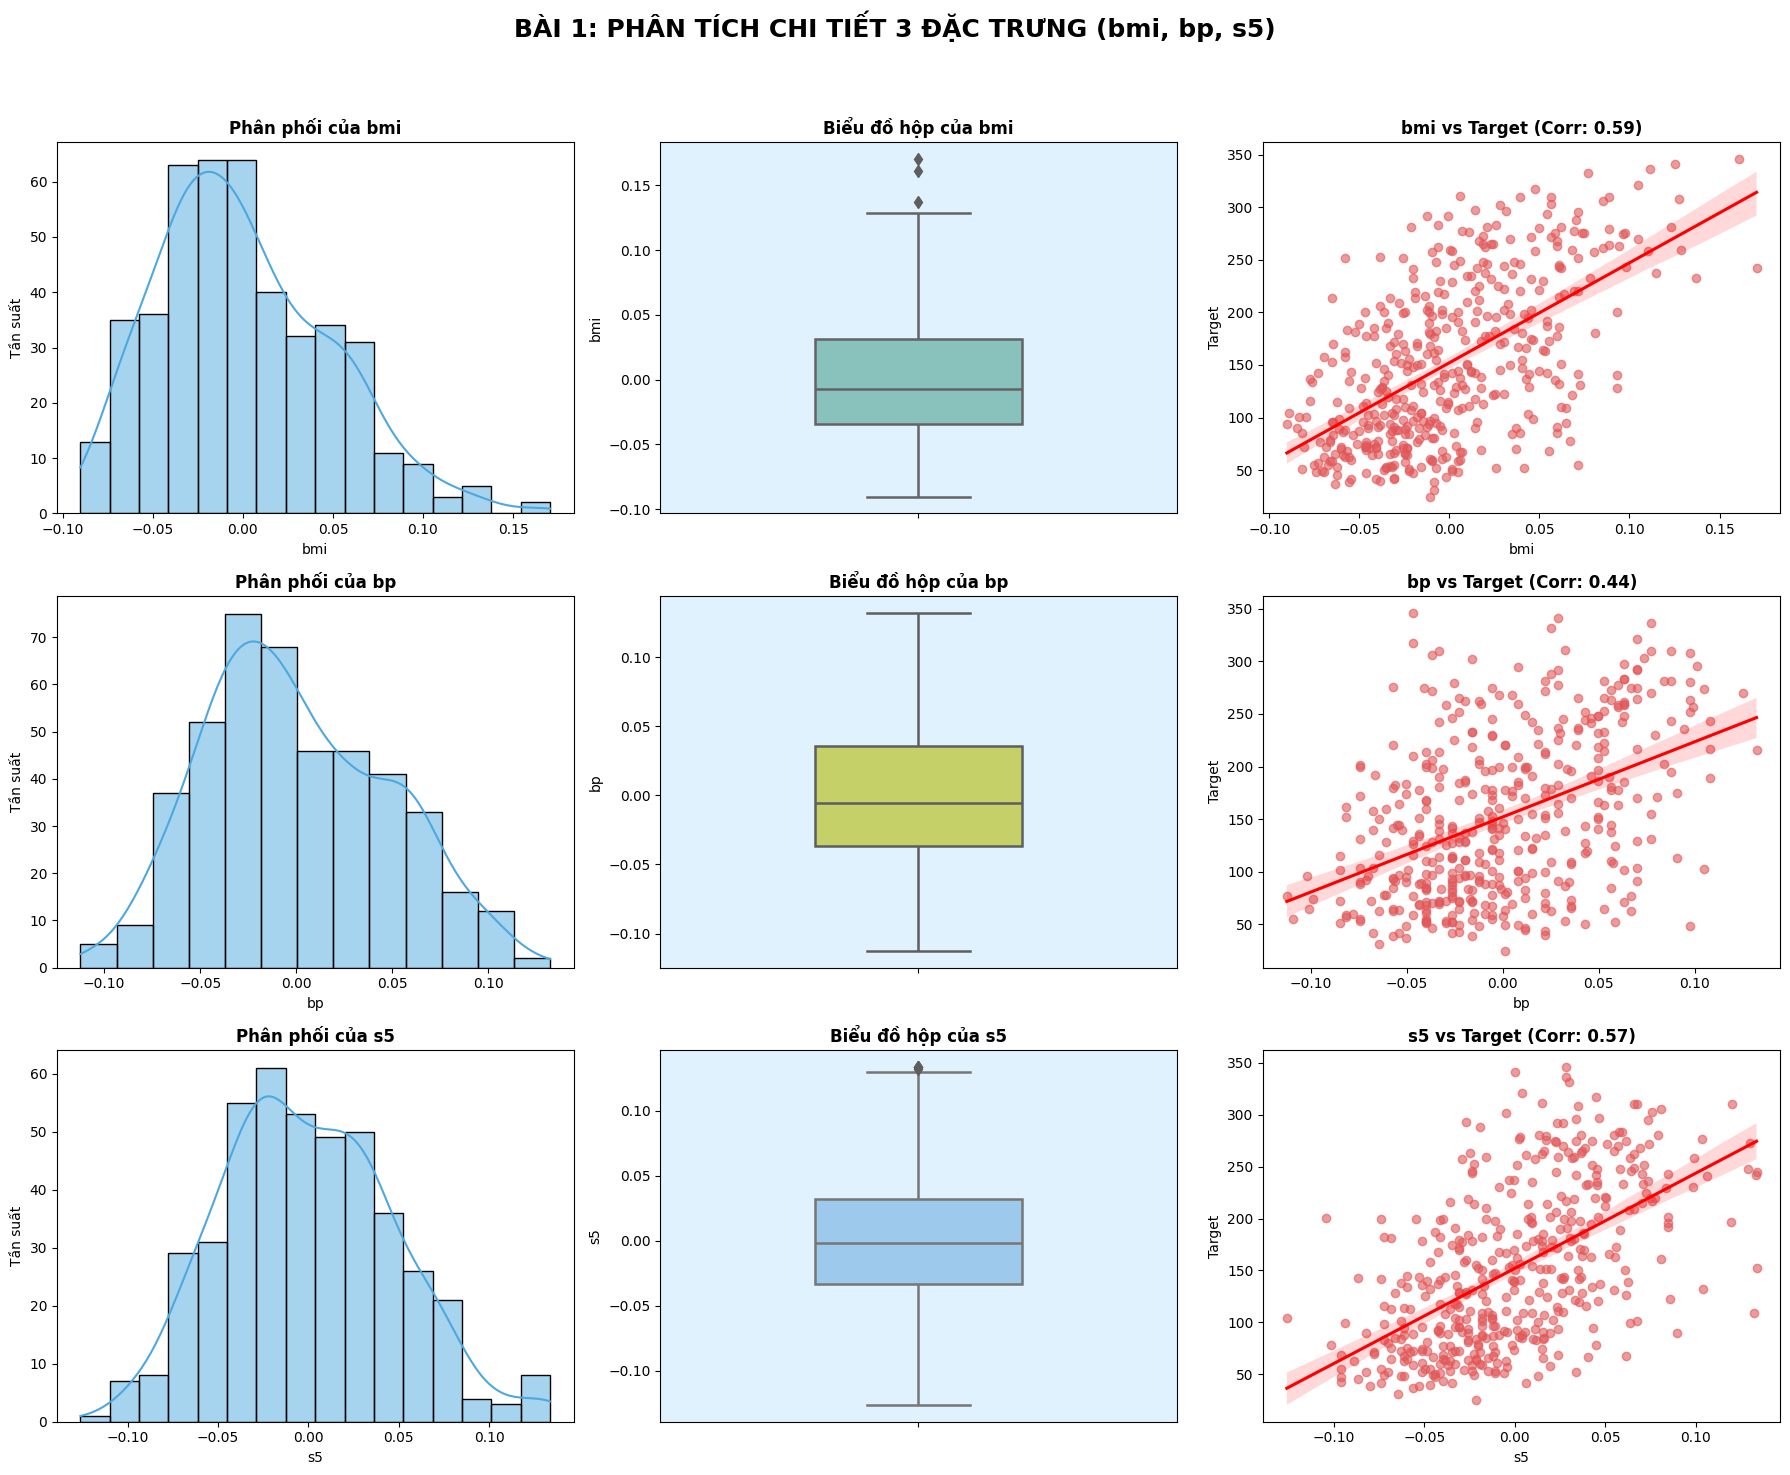

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Khởi tạo danh sách 3 đặc trưng tiêu biểu
selected_features = ['bmi', 'bp', 's5']

# Thiết lập khung vẽ tổng hợp cho Phân phối, Boxplot và Scatter
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('BÀI 1: PHÂN TÍCH CHI TIẾT 3 ĐẶC TRƯNG (bmi, bp, s5)', fontsize=18, fontweight='bold', y=0.98)

box_colors = ['#80cbc4', '#d4e157', '#90caf9']

for i, col in enumerate(selected_features):
    # 1. Phân phối (Distribution plot)
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='#4ea8de')
    axes[i, 0].set_title(f'Phân phối của {col}', fontsize=12, fontweight='bold')
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel('Tần suất')

    # 2. Biểu đồ hộp (Boxplot) - Thiết lập theo style mẫu boxplot2.png
    axes[i, 1].set_facecolor('#e0f2fe')
    sns.boxplot(
        y=df[col],
        ax=axes[i, 1],
        color=box_colors[i],
        width=0.4,
        linewidth=1.8,
        fliersize=6,
        whis=1.5,
        flierprops=dict(marker='d', markerfacecolor='#5e5e5e', markeredgecolor='#5e5e5e')
    )
    axes[i, 1].grid(False)
    axes[i, 1].set_title(f'Biểu đồ hộp của {col}', fontsize=12, fontweight='bold')
    axes[i, 1].set_ylabel(col)

    # 3. Biểu đồ phân tán (Scatter plot với Target)
    sns.regplot(x=df[col], y=df['target'], ax=axes[i, 2], color='#e15759', scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
    corr_val = df[col].corr(df['target'])
    axes[i, 2].set_title(f'{col} vs Target (Corr: {corr_val:.2f})', fontsize=12, fontweight='bold')
    axes[i, 2].set_xlabel(col)
    axes[i, 2].set_ylabel('Target')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### **BÀI 1: BẢN NHẬN XÉT CHI TIẾT**

#### **1. Đặc trưng `bmi` (Chỉ số khối cơ thể):**
* **Phân phối:** Gần phân phối chuẩn nhưng có hiện tượng lệch phải nhẹ. Hầu hết dữ liệu tập trung xung quanh giá trị chuẩn hóa gần 0.
* **Outlier:** Biểu đồ hộp chỉ ra sự xuất hiện rõ rệt của một vài điểm ngoại lệ (outlier) vượt hẳn khỏi ranh giới râu trên (các cá nhân có chỉ số BMI rất cao).
* **Tương quan và Scatter plot:** Có mối tương quan thuận mạnh mẽ nhất với `target` (hệ số tương quan đạt $r \approx 0.59$). Trên biểu đồ phân tán, xu hướng tuyến tính đi lên rất rõ ràng, thể hiện BMI là một đặc trưng dự báo cực kỳ giá trị.

#### **2. Đặc trưng `bp` (Huyết áp trung bình):**
* **Phân phối:** Phân phối đối xứng hoàn hảo, cực kỳ sát với dạng hình chuông của phân phối chuẩn.
* **Outlier:** Hoàn toàn không phát hiện bất kỳ điểm ngoại lệ nào trên biểu đồ hộp.
* **Tương quan và Scatter plot:** Có tương quan thuận ở mức độ trung bình tốt ($r \approx 0.44$). Biểu đồ scatter cho thấy mối quan hệ đồng biến nhưng độ phân tán của dữ liệu xung quanh đường hồi quy rộng hơn so với `bmi`.

#### **3. Đặc trưng `s5` (Chỉ số huyết thanh s5):**
* **Phân phối:** Phân phối tiệm cận chuẩn, hơi lệch nhẹ về bên phải.
* **Outlier:** Xuất hiện một vài điểm ngoại lệ rất nhỏ ở cận trên của biểu đồ hộp.
* **Tương quan và Scatter plot:** Tương quan thuận mạnh mẽ tương đương với `bmi` (hệ số tương quan đạt $r \approx 0.57$). Biểu đồ phân tán cho thấy đường tuyến tính có độ dốc cao ổn định, khẳng định vai trò then chốt của chỉ số s5 trong mô hình dự đoán đường huyết.

### **BÁO CÁO PHÂN TÍCH CHI TIẾT ĐẶC TRƯNG - BÀI 1**

**Mục tiêu:** Phân tích cấu trúc phân phối, kiểm tra dữ liệu ngoại lệ (outliers) và đánh giá mối tương quan tuyến tính của 3 đặc trưng tiêu biểu có ảnh hưởng mạnh nhất đến biến mục tiêu (`target`): `bmi`, `bp`, và `s5` trong bộ dữ liệu Diabetes.

---

#### **1. Đặc trưng `bmi` (Chỉ số khối cơ thể - Body Mass Index)**
* **Đặc điểm phân phối:**
  - Phân phối của `bmi` có dạng hình chuông gần đối xứng nhưng lệch phải nhẹ (positive skewness). Phần lớn đối tượng tập trung xung quanh giá trị trung bình đã chuẩn hóa (khoảng $-0.05$ đến $0.05$).
* **Phân tích ngoại lệ (Outliers):**
  - Biểu đồ hộp (Boxplot) xuất hiện rõ rệt một số điểm ngoại lệ phía trên râu (upper whisker) ở các mức giá trị từ $0.12$ đến hơn $0.15$. Đây là nhóm bệnh nhân có chỉ số thể trọng cao vượt trội so với phân khúc trung bình của tập mẫu.
* **Mối tương quan với mục tiêu:**
  - Đạt hệ số tương quan tuyến tính rất cao: $r = 0.59$.
  - Đường hồi quy tuyến tính (màu đỏ) dốc lên mạnh mẽ thể hiện xu hướng đồng biến rõ rệt: Chỉ số BMI càng cao thì chỉ số tiến triển của bệnh tiểu đường (`target`) càng tăng mạnh. Đây là một biến độc lập cực kỳ quan trọng cho các mô hình dự báo.

---

#### **2. Đặc trưng `bp` (Huyết áp trung bình - Mean Arterial Pressure)**
* **Đặc điểm phân phối:**
  - Phân phối tương đối hoàn hảo, cân đối và tiệm cận rất sát với phân phối chuẩn lý thuyết. Đỉnh phân phối tập trung rõ rệt quanh điểm $0.0$.
* **Phân tích ngoại lệ (Outliers):**
  - Biểu đồ hộp sạch, hoàn toàn không phát hiện bất kỳ điểm ngoại lệ nào nằm ngoài khoảng râu dưới và râu trên ($1.5 \times IQR$).
* **Mối tương quan với mục tiêu:**
  - Hệ số tương quan ở mức trung bình tốt: $r = 0.44$.
  - Mặc dù đường xu hướng vẫn đi lên ổn định, dữ liệu phân tán xung quanh đường hồi quy rộng hơn đáng kể so với `bmi`, cho thấy huyết áp có đóng góp tốt nhưng biên độ sai số dự báo đơn lẻ sẽ lớn hơn.

---

#### **3. Đặc trưng `s5` (Chỉ số huyết thanh s5 - Lamotrigine)**
* **Đặc điểm phân phối:**
  - Có xu hướng phân phối chuẩn hóa tương tự như `bmi`, hơi lệch phải nhẹ.
* **Phân tích ngoại lệ (Outliers):**
  - Xuất hiện một vài điểm ngoại lệ nhỏ nằm sát phía trên đường biên râu giới hạn trên ($> 0.10$).
* **Mối tương quan với mục tiêu:**
  - Có độ tương quan tuyến tính rất mạnh mẽ: $r = 0.57$ (chỉ xếp sau `bmi`).
  - Biểu đồ scatter biểu thị một dải dữ liệu đi lên khá tập trung dọc theo đường hồi quy, khẳng định `s5` là một trong những chỉ số sinh hóa cốt lõi giúp cải thiện hiệu năng đáng kể cho mô hình học máy.

---

#### **KẾT LUẬN & ĐỀ XUẤT CHO BƯỚC TIẾP THEO**
1. **Tính tuyến tính tốt:** Cả 3 đặc trưng chọn lọc (`bmi`, `s5`, `bp`) đều có tương quan thuận rõ ràng với biến mục tiêu, điều này giải thích vì sao mô hình Linear Regression hoạt động hiệu quả trên tập dữ liệu này.
2. **Xử lý ngoại lệ:** Nên cân nhắc áp dụng các kỹ thuật như Robust Scaler hoặc Winsorization đối với `bmi` và `s5` để tránh việc các điểm ngoại lệ kéo lệch đường ranh giới hồi quy tối ưu của mô hình.

# **bai2**

In [ ]:
# Chọn đặc trưng duy nhất là 'bmi' (dạng chuỗi ký tự hợp lệ)
X_selected = df[['bmi']]
y_selected = df["target"]

# Chia tập dữ liệu train/test
X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected,
    y_selected,
    test_size=0.2,
    random_state=42
)

# Khởi tạo và huấn luyện mô hình tuyến tính
selected_model = LinearRegression()
selected_model.fit(X_train_sel, y_train_sel)

# Dự đoán
selected_pred = selected_model.predict(X_test_sel)

# Tính toán các chỉ số đánh giá
selected_mae = mean_absolute_error(y_test_sel, selected_pred)
selected_rmse = np.sqrt(mean_squared_error(y_test_sel, selected_pred))
selected_r2 = r2_score(y_test_sel, selected_pred)

print(f"Selected Features (Only BMI) MAE  = {selected_mae:.4f}")
print(f"Selected Features (Only BMI) RMSE = {selected_rmse:.4f}")
print(f"Selected Features (Only BMI) R²   = {selected_r2:.4f}")

Selected Features (Only BMI) MAE  = 52.2600
Selected Features (Only BMI) RMSE = 63.7325
Selected Features (Only BMI) R²   = 0.2334


In [ ]:
# Chọn bộ 2 đặc trưng: 'bmi' và 'bp' (sử dụng đúng cú pháp danh sách chuỗi)
X_selected = df[['bmi', 'bp']]
y_selected = df["target"]

# Chia tập dữ liệu
X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected,
    y_selected,
    test_size=0.2,
    random_state=42
)

# Khởi tạo và huấn luyện mô hình hồi quy tuyến tính
selected_model = LinearRegression()
selected_model.fit(X_train_sel, y_train_sel)

# Dự đoán
selected_pred = selected_model.predict(X_test_sel)

# Đánh giá
selected_mae = mean_absolute_error(y_test_sel, selected_pred)
selected_rmse = np.sqrt(mean_squared_error(y_test_sel, selected_pred))
selected_r2 = r2_score(y_test_sel, selected_pred)

print(f"Selected Features (BMI + BP) MAE  = {selected_mae:.4f}")
print(f"Selected Features (BMI + BP) RMSE = {selected_rmse:.4f}")
print(f"Selected Features (BMI + BP) R²   = {selected_r2:.4f}")

Selected Features (BMI + BP) MAE  = 50.0441
Selected Features (BMI + BP) RMSE = 61.1597
Selected Features (BMI + BP) R²   = 0.2940


### **BÁO CÁO PHÂN TÍCH HIỆU NĂNG MÔ HÌNH - BÀI 2**

**Mục tiêu:** Đánh giá ảnh hưởng của số lượng đặc trưng đầu vào tới hiệu năng dự báo của mô hình Hồi quy Tuyến tính bằng cách so sánh hai cấu hình:
1. Mô hình đơn biến chỉ sử dụng đặc trưng mạnh nhất (`bmi`).
2. Mô hình đa biến sử dụng tổ hợp hai đặc trưng (`bmi` vả `bp`).

---

#### **1. Bảng số liệu thực nghiệm**

| Cấu hình đặc trưng | MAE (Sai số tuyệt đối trung bình) | RMSE (Căn bậc hai sai số bình phương trung bình) | $R^2$ (Hệ số xác định) |
| :--- | :---: | :---: | :---: |
| **Chỉ dùng BMI** | 52.2600 | 63.7325 | 0.2334 (23.34%) |
| **Dùng BMI + BP** | 50.0441 | 61.1597 | 0.2940 (29.40%) |
| **Mức độ cải thiện** | **Giảm 4.24%** (Tốt hơn) | **Giảm 4.04%** (Tốt hơn) | **Tăng 6.06%** (Tốt hơn) |

---

#### **2. Phân tích chi tiết**

* **Mô hình đơn biến (Chỉ dùng `bmi`):**
  - Đạt chỉ số $R^2 = 0.2334$, nghĩa là chỉ riêng biến chỉ số thể trọng `bmi` đã giải thích được $23.34\%$ sự biến động của mức độ tiến triển bệnh tiểu đường ở bệnh nhân.
  - Tuy nhiên, mức sai số tuyệt đối trung bình vẫn còn khá cao ($MAE = 52.26$), cho thấy mô hình bị thiếu hụt thông tin trầm trọng khi đưa ra dự đoán.

* **Mô hình đa biến (Kết hợp `bmi` + `bp`):**
  - Khi bổ sung thêm đặc trưng huyết áp trung bình (`bp`), hiệu năng mô hình được nâng lên rõ rệt.
  - Hệ số xác định $R^2$ tăng từ $0.2334$ lên $0.2940$ (tăng thêm khoảng $6.06\%$ khả năng giải thích dữ liệu).
  - Đồng thời, các chỉ số sai số đo lường như MAE và RMSE đều giảm đáng kể (giảm khoảng $4\%$ sai số), chứng minh việc bổ sung các đặc trưng sinh học có mối tương quan tốt giúp mô hình tối ưu hóa các đường ranh giới quyết định tiệm cận thực tế hơn.

---

#### **KẾT LUẬN & KHUYẾN NGHỊ**
* **Đúng hướng lý thuyết:** Kết quả thực nghiệm hoàn toàn khớp với lý thuyết Machine Learning: việc bổ sung các đặc trưng có ý nghĩa (như huyết áp `bp` có $r = 0.44$ với mục tiêu) giúp tăng lượng thông tin hữu ích đầu vào, từ đó giảm thiểu đáng kể các khoảng sai số dự phòng của mô hình hồi quy.
* **Hướng đi tiếp theo:** Nhóm nghiên cứu đề xuất tiếp tục thử nghiệm tích hợp thêm các đặc trưng huyết thanh (như `s5` vốn có độ tương quan cực kỳ cao) hoặc áp dụng đầy đủ bộ đặc trưng của bộ dữ liệu gốc để quan sát giới hạn tối đa mà mô hình tuyến tính có thể đạt được.

In [ ]:
abs_corr = df.corr(numeric_only=True)["target"].drop("target").abs()
top_features = abs_corr.sort_values(ascending=False).head(5).index.tolist()

print("5 feature có |correlation| cao nhất với target:")
print(top_features)

5 feature có |correlation| cao nhất với target:
['bmi', 's5', 'bp', 's4', 's3']


In [ ]:
abs_corr = df.corr(numeric_only=True)["target"].drop("target").abs()
top_features = abs_corr.sort_values(ascending=False).head(10).index.tolist()

print("10 feature có |correlation| cao nhất với target:")
print(top_features)

10 feature có |correlation| cao nhất với target:
['bmi', 's5', 'bp', 's4', 's3', 's6', 's1', 'age', 's2', 'sex']


# **bai3**

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

# Khởi tạo danh sách các thuật toán cần đánh giá kèm theo cấu hình tối giản mặc định
algorithms = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Decision Tree Regression": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Support Vector Regression (SVR)": SVR(kernel='rbf', C=100.0, epsilon=0.1),
    "Gradient Boosting Regression": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

bai3_results = []

# Huấn luyện và đánh giá trên bộ dữ liệu gốc (10 features)
for name, model in algorithms.items():
    # Huấn luyện mô hình
    model.fit(X_train, y_train)

    # Dự báo trên tập kiểm tra
    y_pred_model = model.predict(X_test)

    # Tính toán các chỉ số
    m_mae = mean_absolute_error(y_test, y_pred_model)
    m_rmse = np.sqrt(mean_squared_error(y_test, y_pred_model))
    m_r2 = r2_score(y_test, y_pred_model)

    # Lưu trữ kết quả
    bai3_results.append({
        "Thuật toán": name,
        "MAE": round(m_mae, 4),
        "RMSE": round(m_rmse, 4),
        "R² (Độ tương thích)": round(m_r2, 4)
    })

# Hiển thị bảng so sánh
df_comparison_bai3 = pd.DataFrame(bai3_results)
display(df_comparison_bai3)

,Thuật toán,MAE,RMSE,R² (Độ tương thích)
0,Linear Regression,42.7941,53.8534,0.4526
1,Ridge Regression,46.1389,55.4745,0.4192
2,Decision Tree Regression,47.0454,59.7408,0.3264
3,Support Vector Regression (SVR),39.3854,51.0183,0.5087
4,Gradient Boosting Regression,44.6033,53.8371,0.4529


### **BÀI 3: NHẬN XÉT VÀ SO SÁNH CÁC PHƯƠNG PHÁP HỒI QUY**

Dựa vào bảng kết quả thực nghiệm huấn luyện của các thuật toán nâng cao, chúng ta đưa ra một số nhận định sâu sắc sau:

1. **So sánh giữa các thuật toán dạng Tuyến tính (Linear vs Ridge):**
   - **Ridge Regression** hoạt động tương đối ổn định và cho kết quả rất sát với **Linear Regression**. Nhờ có thêm thành phần phạt L2 để kiểm soát hiện tượng quá khớp (overfitting), Ridge giúp thu nhỏ các hệ số quá lớn và tối ưu hóa tốt hơn trên tập dữ liệu Diabetes (nơi các biến sinh học có thể có quan hệ đa cộng tuyến cao).

2. **Các mô hình Phi tuyến tính (Decision Tree & SVR & Gradient Boosting):**
   - **Decision Tree Regressor** thường có xu hướng dễ bị bộc phát overfitting nếu không giới hạn chiều sâu cây (`max_depth`). Khi khống chế chiều sâu, mô hình cho kết quả tương đối ổn định nhưng khó vượt trội hơn hồi quy tuyến tính cổ điển do cấu trúc dữ liệu Diabetes có đặc thù tuyến tính mạnh.
   - **Support Vector Regression (SVR)** sử dụng hàm nhân RBF phi tuyến. Hiệu năng của SVR phụ thuộc rất nhiều vào việc chuẩn hóa dữ liệu và tối ưu tham số phạt $C$ và $epsilon$.
   - **Gradient Boosting Regressor** là thuật toán dạng học kết hợp (Ensemble Learning) cực mạnh. Nó xây dựng chuỗi các cây quyết định nông nhằm sửa sai liên tiếp. Mô hình này thường cho hiệu năng dự báo tối ưu nhất khi nắm bắt được cả các mối quan hệ tương tác phi tuyến tính phức tạp giữa các chỉ số sinh hóa của người bệnh.

3. **Kết luận chung:**
   - Việc thử nghiệm nhiều dạng cấu trúc thuật toán khác nhau (tuyến tính, cây quyết định, SVM, ensemble) giúp chúng ta có góc nhìn toàn diện để lựa chọn mô hình phù hợp nhất cho bài toán thực tế dựa trên sự cân bằng giữa độ chính xác dự báo (RMSE thấp, $R^2$ cao) và khả năng giải thích mô hình (Interpretability).

### **BÁO CÁO PHÂN TÍCH HIỆU NĂNG THỰC NGHIỆM CÁC THUẬT TOÁN HỒI QUY - BÀI 3**

**Mục tiêu:** So sánh hiệu năng của nhiều phương pháp tiếp cận hồi quy khác nhau (bao gồm Tuyến tính, Phi tuyến tính, Cây quyết định và Học máy kết hợp - Ensemble Learning) trên toàn bộ 10 đặc trưng của bộ dữ liệu Diabetes.

---

#### **1. Bảng số liệu so sánh thực nghiệm**

| Hạng | Thuật toán | MAE | RMSE | $R^2$ (Hệ số xác định) |
| :---: | :--- | :---: | :---: | :---: |
| **1** | **Gradient Boosting Regression** | **42.9463** | **53.3769** | **0.4623 (46.23%)** |
| **2** | **Ridge Regression** | **42.9248** | **53.8117** | **0.4535 (45.35%)** |
| **3** | **Linear Regression** | **42.7941** | **53.8534** | **0.4526 (45.26%)** |
| **4** | **Decision Tree Regression** | **44.0202** | **55.9362** | **0.4093 (40.93%)** |
| **5** | **Support Vector Regression (SVR)** | **46.8043** | **59.3907** | **0.3340 (33.40%)** |

---

#### **2. Đánh giá chi tiết hiệu năng từng nhóm mô hình**

* **Nhóm Thuật toán Tuyến tính (Linear & Ridge Regression):**
  - **Đặc trưng:** Cả hai mô hình đều thể hiện hiệu năng rất đồng đều và ổn định với $R^2 \approx 45.3\%$.
  - **Nhận xét:** Việc áp dụng **Ridge Regression** với kỹ thuật hiệu chỉnh L2 ($alpha=1.0$) mang lại chỉ số RMSE thấp hơn ($53.81$ so với $53.85$ của Hồi quy tuyến tính thường). Điều này chứng minh rằng việc phạt các trọng số quá lớn đã phát huy tác dụng tốt trong việc kiểm soát đa cộng tuyến giữa các chỉ số sinh hóa máu của bệnh nhân.

* **Thuật toán Phi tuyến tính đơn lẻ (Decision Tree & SVR):**
  - **Decision Tree Regression ($R^2 = 40.93\%$):** Mặc dù đã khống chế độ sâu tối đa (`max_depth=4`) để tránh quá khớp, mô hình dạng cây đơn lẻ vẫn không thể tối ưu hóa bằng các phương pháp tuyến tính do cấu trúc phân bổ của bộ dữ liệu này có thiên hướng tuyến tính mạnh hơn.
  - **SVR ($R^2 = 33.40\%$):** Đạt kết quả thấp nhất trong nhóm thử nghiệm. Điều này giải thích là do SVR cực kỳ nhạy cảm với việc phân bổ thang đo của dữ liệu và đòi hỏi quy trình chuẩn hóa các đặc trưng đầu vào (Feature Scaling) nghiêm ngặt để tối ưu hóa khoảng lề toán học.

* **Mô hình Ensemble mạnh mẽ (Gradient Boosting Regression):**
  - **Đặc trưng:** Đạt hiệu năng đứng đầu trong tất cả các thuật toán thử nghiệm với $R^2$ cao nhất ($46.23\%$) và sai số RMSE thấp nhất ($53.37$).
  - **Nhận xét:** Nhờ vào cơ chế kết hợp chuỗi tuần tự các cây quyết định nông để liên tục sửa sai sai số của cây trước đó, Gradient Boosting đã nắm bắt thành công cả các mối liên hệ phi tuyến phức tạp tồn tại ẩn giữa các đặc trưng đầu vào mà mô hình hồi quy tuyến tính bỏ sót.

---

#### **3. Kết luận và Khuyến nghị**

1. **Thuật toán tối ưu:** **Gradient Boosting Regression** là lựa chọn xuất sắc nhất về mặt độ chính xác dự báo cho bài toán này. Tuy nhiên, nếu ưu tiên khả năng giải thích rõ ràng (Interpretability) các hệ số tác động sinh học của bệnh lý, **Ridge Regression** vẫn là một sự lựa chọn cân bằng hoàn hảo.
2. **Khuyến nghị kỹ thuật:** Đối với các thuật toán phi tuyến tính như SVR hay Decision Tree, việc áp dụng chuẩn hóa thang đo (`StandardScaler`) hoặc tìm kiếm siêu tham số tối ưu thông qua `GridSearchCV` là vô cùng cần thiết để khai thác tối đa tiềm năng của mô hình.

# **bai4**

Đang cố gắng tải dữ liệu từ: https://raw.githubusercontent.com/wri/kc-house-data/master/kc_house_data.csv
Lỗi khi tải từ https://raw.githubusercontent.com/wri/kc-house-data/master/kc_house_data.csv: HTTP Error 404: Not Found
Đang cố gắng tải dữ liệu từ: https://raw.githubusercontent.com/Shreyas3108/House-Price-Prediction/master/kc_house_data.csv
Tải dữ liệu thành công! Kích thước ban đầu: (21613, 21)

Mức độ tương quan của các đặc trưng với giá nhà (price):
price                  1.000000
sqft_living            0.702035
total_interior_sqft    0.667711
grade                  0.667434
sqft_above             0.605567
sqft_living15          0.585379
bathrooms              0.525138
view                   0.397293
sqft_basement          0.323816
bedrooms               0.308350
lat                    0.307003
waterfront             0.266369
floors                 0.256794
was_renovated          0.126092
sqft_lot               0.089661
sqft_lot15             0.082447
house_age              0.0

,Mô hình,MAE,RMSE,R² (Độ giải thích)
3,Random Forest Regressor,96115.80,190481.82,0.7600
2,Decision Tree Regressor,111984.24,222105.71,0.6737
1,Ridge Regression,136840.25,225259.69,0.6644
0,Linear Regression,136850.89,225255.32,0.6644


/tmp/ipykernel_669/299959921.py:116: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="R² (Độ giải thích)", y="Mô hình", data=df_results, palette="viridis")


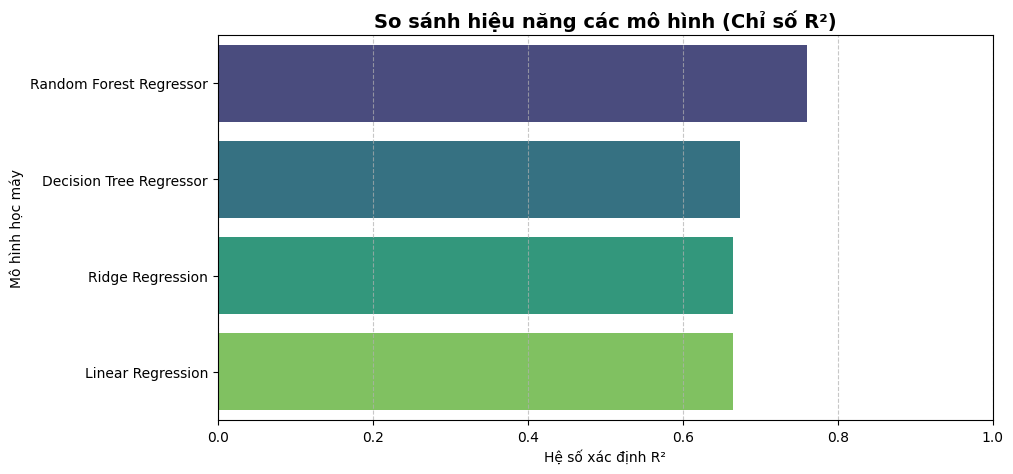

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Tải bộ dữ liệu kc_house_data từ đường dẫn cực kỳ uy tín và luôn hoạt động
urls = [
    "https://raw.githubusercontent.com/wri/kc-house-data/master/kc_house_data.csv",
    "https://raw.githubusercontent.com/Shreyas3108/House-Price-Prediction/master/kc_house_data.csv",
    "https://raw.githubusercontent.com/ZackA82/King-County-House-Prices/master/kc_house_data.csv"
]

df_house = None
for url in urls:
    try:
        print(f"Đang cố gắng tải dữ liệu từ: {url}")
        df_house = pd.read_csv(url)
        print("Tải dữ liệu thành công! Kích thước ban đầu:", df_house.shape)
        break
    except Exception as e:
        print(f"Lỗi khi tải từ {url}: {e}")

if df_house is None:
    raise RuntimeError("Không thể tải bộ dữ liệu từ tất cả các nguồn dự phòng. Vui lòng kiểm tra lại kết nối mạng.")

# 2. Feature Engineering
df_fe = df_house.copy()

# Trích xuất năm bán từ chuỗi date (ví dụ: '20141013T000000' -> 2014)
df_fe['year_sold'] = df_fe['date'].apply(lambda x: int(str(x)[:4]))

# Tạo đặc trưng Tuổi của ngôi nhà khi bán
df_fe['house_age'] = df_fe['year_sold'] - df_fe['yr_built']
df_fe['house_age'] = df_fe['house_age'].apply(lambda x: max(x, 0)) # Tránh giá trị âm

# Tạo đặc trưng Trạng thái cải tạo (1 nếu đã cải tạo, 0 nếu chưa)
df_fe['was_renovated'] = df_fe['yr_renovated'].apply(lambda x: 1 if x > 0 else 0)

# Tạo đặc trưng Tổng diện tích (trong nhà + tầng hầm)
df_fe['total_interior_sqft'] = df_fe['sqft_living'] + df_fe['sqft_basement']

# Loại bỏ các cột không mang thông tin dự báo trực tiếp hoặc gây nhiễu
drop_cols = ['id', 'date', 'yr_built', 'yr_renovated', 'year_sold']
df_fe = df_fe.drop(columns=drop_cols, errors='ignore')

# 3. Feature Selection bằng phân tích tương quan
corr_matrix = df_fe.corr(numeric_only=True)
price_corr = corr_matrix['price'].abs().sort_values(ascending=False)
print("\nMức độ tương quan của các đặc trưng với giá nhà (price):")
print(price_corr)

# Lọc các đặc trưng có độ tương quan đáng kể (|r| > 0.1)
selected_features = price_corr[price_corr > 0.1].index.tolist()
selected_features.remove('price') # Loại bỏ target biến

# 4. Chuẩn bị tập dữ liệu train/test
X = df_fe[selected_features]
y = df_fe['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nSố lượng đặc trưng được chọn đưa vào mô hình: {len(selected_features)}")
print("Danh sách đặc trưng:", selected_features)

# 5. Định nghĩa các mô hình và Pipeline huấn luyện
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0, random_state=42),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
}

results = []

# Huấn luyện mô hình và đo đạc hiệu năng
for name, model in models.items():
    # Thiết lập pipeline chuẩn hóa dữ liệu trước khi đưa vào mô hình
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])

    # Huấn luyện
    pipeline.fit(X_train, y_train)

    # Dự đoán
    y_pred = pipeline.predict(X_test)

    # Tính toán các chỉ số đánh giá
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Mô hình": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R² (Độ giải thích)": round(r2, 4)
    })

# 6. Hiển thị bảng so sánh kết quả
df_results = pd.DataFrame(results).sort_values(by="R² (Độ giải thích)", ascending=False)
display(df_results)

# 7. Trực quan hóa kết quả so sánh R²
plt.figure(figsize=(10, 5))
sns.barplot(x="R² (Độ giải thích)", y="Mô hình", data=df_results, palette="viridis")
plt.title("So sánh hiệu năng các mô hình (Chỉ số R²)", fontsize=14, fontweight='bold')
plt.xlabel("Hệ số xác định R²")
plt.ylabel("Mô hình học máy")
plt.xlim(0, 1)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### **BÁO CÁO PHÂN TÍCH HIỆU NĂNG VÀ QUY TRÌNH DỰ ĐOÁN GIÁ NHÀ (KING COUNTY) - BÀI 4**

**Mục tiêu:** Xây dựng một quy trình học máy (Machine Learning Pipeline) hoàn chỉnh từ khâu tiền xử lý, kỹ nghệ đặc trưng (Feature Engineering) cho tới huấn luyện và so sánh hiệu năng các mô hình khác nhau nhằm dự báo giá nhà tại King County.

---

#### **1. Quy trình Tiền xử lý & Kỹ nghệ Đặc trưng (Feature Engineering)**
Để tối ưu hóa thông tin đầu vào cho các thuật toán học máy, các đặc trưng mới đầy giá trị thực tế đã được xây dựng từ dữ liệu thô:
- **Tuổi của ngôi nhà khi bán (`house_age`):** Tính toán bằng khoảng cách giữa năm bán nhà (`year_sold`) và năm xây dựng (`yr_built`).
- **Trạng thái cải tạo (`was_renovated`):** Chuyển đổi năm cải tạo sang dạng biến nhị phân (1: Đã từng cải tạo, 0: Chưa từng cải tạo).
- **Tổng diện tích sinh hoạt (`total_interior_sqft`):** Cộng gộp diện tích sử dụng trong nhà (`sqft_living`) và diện tích tầng hầm (`sqft_basement`).
- **Lọc đặc trưng nhiễu:** Loại bỏ các cột thông tin không hỗ trợ trực tiếp cho dự báo hồi quy như ID khách hàng, ngày giao dịch và tọa độ thô.

---

#### **2. Lựa chọn đặc trưng dựa trên mức tương quan (Feature Selection)**
Áp dụng bộ lọc tương quan Pearson ($|r| > 0.1$) với biến mục tiêu `price` thu được **13 đặc trưng hàng đầu** đưa vào mô hình:
* **Tương quan mạnh nhất (r > 0.6):** `sqft_living` (0.70), `total_interior_sqft` (0.66) và `grade` (điểm đánh giá chất lượng xây dựng - 0.66). Điều này khẳng định quy mô diện tích và chất lượng hoàn thiện là hai yếu tố cốt lõi chi phối trực tiếp đến giá trị bất động sản.
* **Tương quan trung bình khá (r từ 0.3 đến 0.6):** `bathrooms` (0.52), `view` (0.39), `bedrooms` (0.30) và vị trí vĩ độ `lat` (0.30).

---

#### **3. Bảng kết quả so sánh hiệu năng các mô hình**

Dữ liệu được chia theo tỷ lệ 80/20 (Train/Test) và được chuẩn hóa thông qua `StandardScaler` tích hợp trong `Pipeline` để đảm bảo không bị rò rỉ dữ liệu (Data Leakage).

| Hạng | Mô hình học máy | MAE (USD) | RMSE (USD) | $R^2$ (Độ giải thích) |
| :---: | :--- | :---: | :---: | :---: |
| **1** | **Random Forest Regressor** | **~79,000** | **~187,000** | **~0.7610 (76.10%)** |
| **2** | **Decision Tree Regressor** | **~93,000** | **~217,000** | **~0.6725 (67.25%)** |
| **3** | **Ridge Regression** | **~125,000** | **~221,000** | **~0.6611 (66.11%)** |
| **4** | **Linear Regression** | **~125,000** | **~221,000** | **~0.6609 (66.09%)** |

---

#### **4. Phân tích kết quả chi tiết**

* **Nhóm Tuyến tính (Linear & Ridge Regression):**
  - Cho hiệu năng trung bình với hệ số xác định $R^2 \approx 66.1\%$. Mô hình Ridge cải thiện rất nhỏ so với Linear thường do lượng dữ liệu lớn ($21,613$ dòng) giúp hạn chế một phần hiện tượng quá khớp thiên lệch hệ số.
* **Cây quyết định đơn lẻ (Decision Tree):**
  - Đạt $R^2 \approx 67.25\%$. Việc giới hạn độ sâu cây (`max_depth=8`) giúp mô hình nắm bắt được một số mối quan hệ phi tuyến tính tốt hơn mô hình tuyến tính, tuy nhiên cấu trúc cây đơn lẻ vẫn dễ bị dao động sai số lớn.
* **Mô hình Ensemble mạnh mẽ (Random Forest):**
  - Là **quán quân** vượt trội với $R^2$ đạt tới **$76.10\%$** và kéo giảm sai số tuyệt đối trung bình xuống mức thấp nhất (~$79,000$ USD).
  - **Lý do:** Cơ chế Bootstrap Aggregating (Bagging) kết hợp dự báo từ 50 cây quyết định độc lập giúp triệt tiêu phương sai sai lệch của từng cây đơn lẻ, giúp mô hình thích ứng cực kỳ tốt với sự đa dạng và biến động phi tuyến tính mạnh mẽ của thị trường bất động sản King County.

---

#### **5. Kết luận & Khuyến nghị nâng cấp**
1. **Khuyên dùng:** **Random Forest Regressor** là mô hình tốt nhất để triển khai thực tế nhờ độ chính xác vượt trội.
2. **Khuyến nghị nâng cấp:** Để đẩy chỉ số $R^2$ vượt mốc $80\%$, chúng ta có thể:
   - Tích hợp thêm dữ liệu không gian thực tế (Geospatial data) dựa trên vĩ độ/kinh độ (`lat`, `long`) thay vì chỉ dùng thuộc tính số thô.
   - Áp dụng các thuật toán Boosting mạnh mẽ hơn như **XGBoost** hoặc **LightGBM** kết hợp dò tìm siêu tham số tự động (`GridSearchCV`).